In [1]:
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import pysdds

from opal import load_single_screen

# Screen at 1 mm

In [2]:
sim_dir = "../data/opal/saved_runs/1nc_yag4"
#sim_dir = "opal_sim/tmp_run/"

In [3]:
cathode_screen = load_single_screen(os.path.join(sim_dir, "cathode_screen.h5"))
cathode_screen

{'data': {'id': array([     4,      9,     14, ..., 262088, 262096, 262104]),
  'm': array([12.16661294, 12.16661294, 12.16661294, ..., 12.16661294,
         12.16661294, 12.16661294]),
  'px': array([-0.00479503, -0.00724289, -0.00313893, ...,  0.00685348,
          0.0042637 ,  0.00836157]),
  'py': array([-0.00126026, -0.0058651 , -0.00083094, ...,  0.00644697,
          0.00066113,  0.00430649]),
  'pz': array([0.42450989, 0.42101195, 0.42438805, ..., 0.42257274, 0.42055431,
         0.42160581]),
  'q': array([-3.81469727e-15, -3.81469727e-15, -3.81469727e-15, ...,
         -3.81469727e-15, -3.81469727e-15, -3.81469727e-15]),
  'time': array([1.25029384e-11, 1.25518623e-11, 1.25134203e-11, ...,
         2.11356633e-11, 2.11773556e-11, 2.11692114e-11]),
  'x': array([-0.00122484, -0.00117146, -0.00075654, ...,  0.00067395,
          0.00039296,  0.00101002]),
  'y': array([-2.03608471e-04, -1.34204851e-03, -2.69802720e-04, ...,
          9.10302633e-04,  9.90407293e-06,  5.95833610

In [4]:
cathode_screen['attributes']['SPOS']

array([0.001])

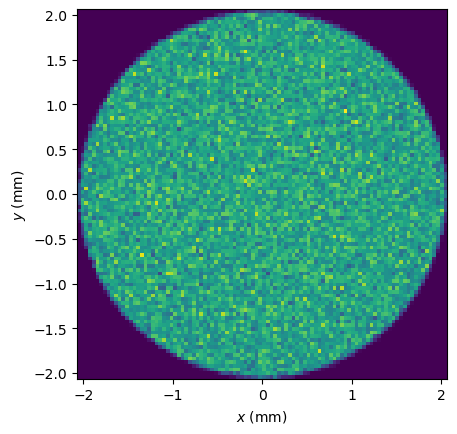

In [5]:
fig, ax = plt.subplots()
ax.hist2d(
    cathode_screen['data']['x']*1e3, 
    cathode_screen['data']['y']*1e3, 
    bins=100
)
ax.set_xlabel('$x$ (mm)')
ax.set_ylabel('$y$ (mm)')
ax.set_aspect('equal')
plt.show()

# Beam stats along beamline

In [6]:
# load beam stats
sdds = pysdds.read(os.path.join(sim_dir, 'input.sdds'))
sdds.column_names

/Users/jp/Repositories/pysdds/pysdds/readers/readers.py:2623: FutureWarning: The 'delim_whitespace' keyword in pd.read_table is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_table(buf, encoding="ascii", **opts)


['t',
 's',
 'numParticles',
 'charge',
 'energy',
 'rms_x',
 'rms_y',
 'rms_s',
 'rms_px',
 'rms_py',
 'rms_ps',
 'emit_x',
 'emit_y',
 'emit_s',
 'mean_x',
 'mean_y',
 'mean_s',
 'ref_x',
 'ref_y',
 'ref_z',
 'ref_px',
 'ref_py',
 'ref_pz',
 'max_x',
 'max_y',
 'max_s',
 'xpx',
 'ypy',
 'zpz',
 'Dx',
 'DDx',
 'Dy',
 'DDy',
 'Bx_ref',
 'By_ref',
 'Bz_ref',
 'Ex_ref',
 'Ey_ref',
 'Ez_ref',
 'dE',
 'dt',
 'partsOutside',
 'DebyeLength',
 'plasmaParameter',
 'temperature',
 'rmsDensity']

In [7]:
stats = sdds.columns_to_df()
stats

,t,s,numParticles,charge,energy,rms_x,rms_y,rms_s,rms_px,rms_py,...,Ex_ref,Ey_ref,Ez_ref,dE,dt,partsOutside,DebyeLength,plasmaParameter,temperature,rmsDensity
0,-0.004186,0.000000,47,-1.792908e-13,0.000001,0.000967,0.001039,2.327115e-08,0.000838,0.000867,...,0.0,0.0,-45.551436,0.000001,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
1,-0.004011,0.000000,1056,-4.028320e-12,0.000002,0.000995,0.000991,5.616857e-08,0.000842,0.000847,...,0.0,0.0,-45.609745,0.000003,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
2,-0.003837,0.000000,5643,-2.152634e-11,0.000005,0.000995,0.000999,1.149729e-07,0.000854,0.000843,...,0.0,0.0,-45.667962,0.000005,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
3,-0.003663,0.000000,11233,-4.285049e-11,0.000011,0.001002,0.000996,2.366080e-07,0.000849,0.000843,...,0.0,0.0,-45.726086,0.000011,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
4,-0.003488,0.000000,16978,-6.476593e-11,0.000021,0.000999,0.001001,4.290433e-07,0.000847,0.000846,...,0.0,0.0,-45.784118,0.000020,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
732,37.976325,11.370287,262144,-1.000000e-09,41.929732,0.002025,0.002022,8.130854e-04,0.007046,0.007065,...,0.0,0.0,0.000000,0.054916,0.010000,0.0,0.000019,10.928376,28.519824,3.680783e+14
733,38.076325,11.400264,262144,-1.000000e-09,41.929728,0.002023,0.002020,8.130808e-04,0.007040,0.007058,...,0.0,0.0,0.000000,0.054892,0.010000,0.0,0.000019,10.884232,28.468501,3.690703e+14
734,38.176325,11.430241,262144,-1.000000e-09,41.929724,0.002020,0.002017,8.130761e-04,0.007034,0.007052,...,0.0,0.0,0.000000,0.054868,0.010000,0.0,0.000019,10.840192,28.417158,3.700658e+14
735,38.276325,11.460218,262144,-1.000000e-09,41.929720,0.002018,0.002015,8.130715e-04,0.007027,0.007046,...,0.0,0.0,0.000000,0.054844,0.010000,0.0,0.000019,10.796256,28.365796,3.710645e+14


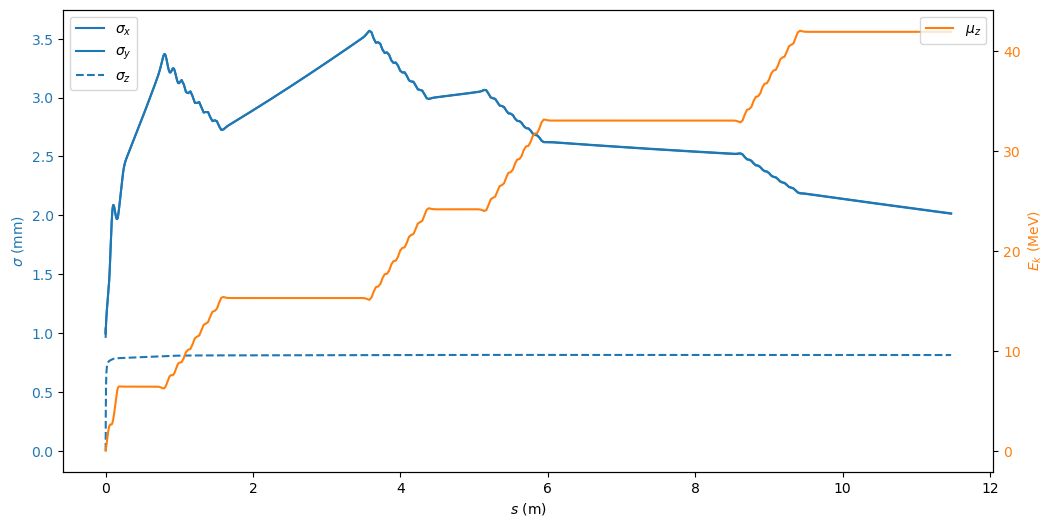

In [8]:
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(stats['s'], stats['rms_x']*1e3, color=colors[0], label='$\sigma _x$')
ax.plot(stats['s'], stats['rms_y']*1e3, color=colors[0], label='$\sigma _y$')
ax.plot(stats['s'], stats['rms_s']*1e3, color=colors[0], linestyle='--', label='$\sigma _z$')
ax.legend(loc='upper left')
ax.set_xlabel('$s$ (m)')
ax.set_ylabel('$\sigma$ (mm)', color=colors[0])
ax.tick_params(axis='y', labelcolor=colors[0])

ax2 = ax.twinx()
ax2.plot(stats['s'], stats['energy'], color=colors[1], label='$\mu _z$')
ax2.legend(loc='upper right')
ax2.set_ylabel('$E_k$ (MeV)', color=colors[1])
ax2.tick_params(axis='y', labelcolor=colors[1])

plt.show()

In [9]:
# include element positions for better plotting

# load design path
col_names = ['s', 'z']
design_path = pd.read_csv(
    os.path.join(sim_dir, 'data', 'input_DesignPath.dat'), 
    sep='\s+',
    skiprows=1,
    usecols=[0,3],
    names=col_names
)

# define function that transforms s to z using the design path
def z_to_s(z_value):
    idx = np.abs(design_path['z'] - z_value).argmin(axis=-1)
    return design_path['s'][idx]
z_to_s = np.vectorize(z_to_s)

# load element positions
col_names = ['label', 'z', 'x', 'y']
ele_pos = pd.read_csv(
    os.path.join(sim_dir, 'data', 'input_ElementPositions.txt'), 
    sep='\s+', 
    index_col=0, 
    names=col_names
)
# get s coordinate for each element
ele_pos['s'] = z_to_s(ele_pos['z'])
ele_pos

,z,x,y,s
label,,,,
BEGIN: CATHODE,0.000000,0,0,0.000457
END: CATHODE,0.050000,0,0,0.051185
BEGIN: YAG4,11.372000,0,0,11.371538
END: YAG4,11.382000,0,0,11.380531
BEGIN: SCREEN_CATHODE,0.001000,0,0,0.000457
END: SCREEN_CATHODE,0.011000,0,0,0.010726
BEGIN: GUN,0.000000,0,0,0.000457
END: GUN,0.292707,0,0,0.292677
BEGIN: LINAC_1,0.577433,0,0,0.576703


In [10]:
# elements I want to plot
elements = {
    'linacs': ['GUN', 'LINAC_1', 'LINAC_2', 'LINAC_3', 'LINAC_5'],
#    'dipoles': ['ED1', 'ED2', 'ED3', 'ED4'],
#    'quads':  ['DQ4', 'DQ5', 'DQ6', 'DQ7'],
#    'rquads':  ['RQ1', 'RQ2'],
}

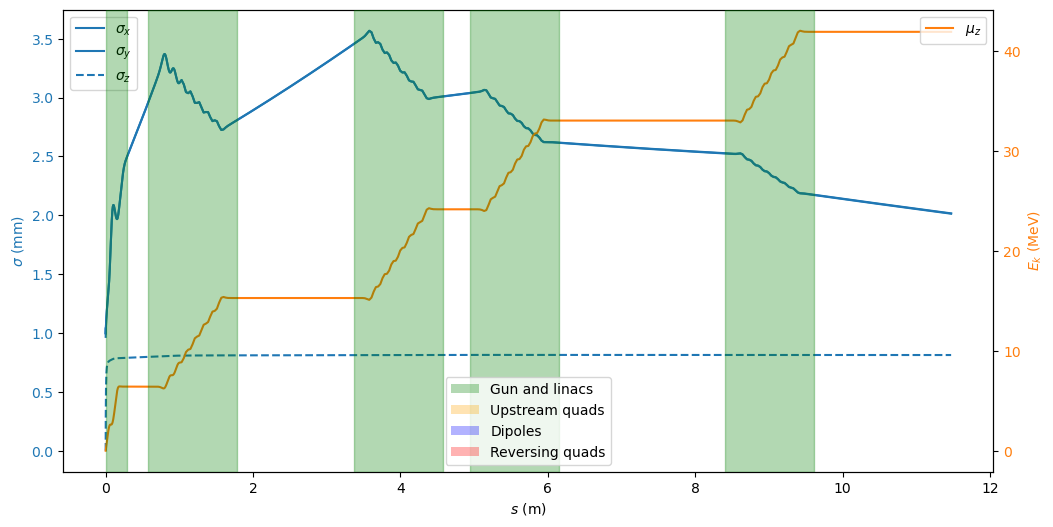

In [53]:
from matplotlib.patches import Patch

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(stats['s'], stats['rms_x']*1e3, color=colors[0], label='$\sigma _x$')
ax.plot(stats['s'], stats['rms_y']*1e3, color=colors[0], label='$\sigma _y$')
ax.plot(stats['s'], stats['rms_s']*1e3, color=colors[0], linestyle='--', label='$\sigma _z$')
ax.legend(loc='upper left')
ax.set_xlabel('$s$ (m)')
ax.set_ylabel('$\sigma$ (mm)', color=colors[0])
ax.tick_params(axis='y', labelcolor=colors[0])

ax2 = ax.twinx()
ax2.plot(stats['s'], stats['energy'], color=colors[1], label='$\mu _z$')
ax2.legend(loc='upper right')
ax2.set_ylabel('$E_k$ (MeV)', color=colors[1])
ax2.tick_params(axis='y', labelcolor=colors[1])

ax3 = ax.twinx()
for linac in elements['linacs']:
    begin = ele_pos.at[f'BEGIN: {linac}', 'z']
    end = ele_pos.at[f'END: {linac}', 'z']
    ax3.axvspan(begin, end, alpha=0.3 , color='green')
ax3.axis('off')
legend_elements = [
    Patch(facecolor='green', alpha=0.3),
    Patch(facecolor='orange', alpha=0.3),
    Patch(facecolor='blue', alpha=0.3),
    Patch(facecolor='red', alpha=0.3),
]
legend_labels = [
    'Gun and linacs',
    'Upstream quads',
    'Dipoles',
    'Reversing quads',
]
ax3.legend(legend_elements, legend_labels, loc='lower center')
plt.show()

# Phase space at YAG4

In [22]:
yag4 = load_single_screen(os.path.join(sim_dir, 'YAG4.h5'))

In [24]:
yag4

{'data': {'id': array([ 35606,  46607,   6507, ..., 205475, 221221, 119062]),
  'm': array([12.16661294, 12.16661294, 12.16661294, ..., 12.16661294,
         12.16661294, 12.16661294]),
  'px': array([ 0.00551783,  0.00093782,  0.00612115, ...,  0.00061827,
         -0.00379052, -0.00244209]),
  'py': array([ 0.00403938,  0.00568051,  0.00655424, ..., -0.0081647 ,
          0.00079223,  0.00010716]),
  'pz': array([82.88738871, 82.89893425, 82.97619735, ..., 83.18774117,
         83.18610644, 83.0418974 ]),
  'q': array([-3.81469727e-15, -3.81469727e-15, -3.81469727e-15, ...,
         -3.81469727e-15, -3.81469727e-15, -3.81469727e-15]),
  'time': array([3.79798526e-08, 3.79802119e-08, 3.79786823e-08, ...,
         3.79859405e-08, 3.79865895e-08, 3.79828598e-08]),
  'x': array([-2.06839208e-03, -6.99162331e-04, -1.48690242e-03, ...,
          1.98624237e-05,  1.02701688e-03,  6.86106825e-04]),
  'y': array([-1.52446417e-03, -2.01346771e-03, -1.47493464e-03, ...,
          2.30537796e-03

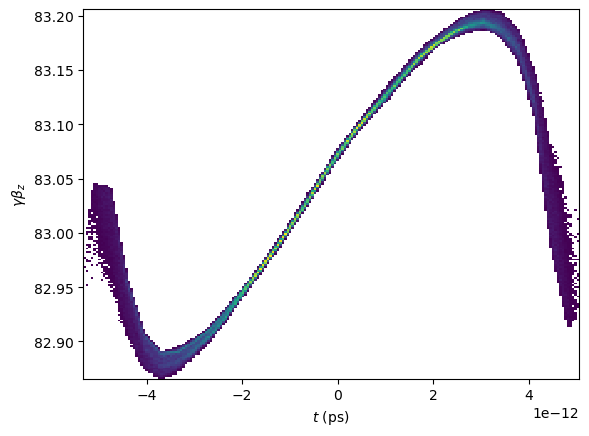

In [46]:
plt.hist2d(
    yag4['data']['time'] - yag4['data']['time'].mean(), 
    yag4['data']['pz'],
    bins=200,
    cmin=1
)
plt.xlabel('$t$ (ps)')
plt.ylabel('$\gamma \\beta_z$')
plt.show()

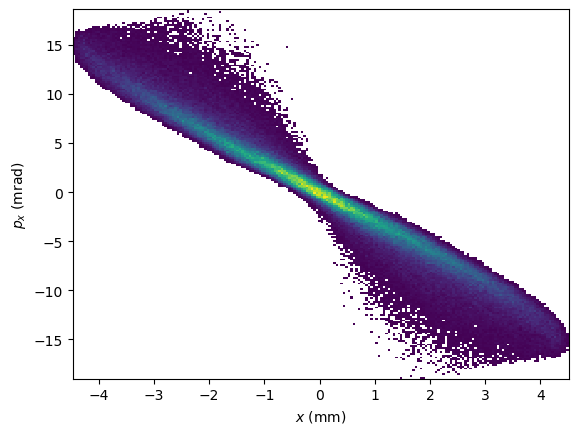

In [50]:
plt.hist2d(
    yag4['data']['x']*1e3, 
    yag4['data']['px']*1e3,
    bins=200,
    cmin=1
)
plt.xlabel('$x$ (mm)')
plt.ylabel('$p_x$ (mrad)')
plt.show()

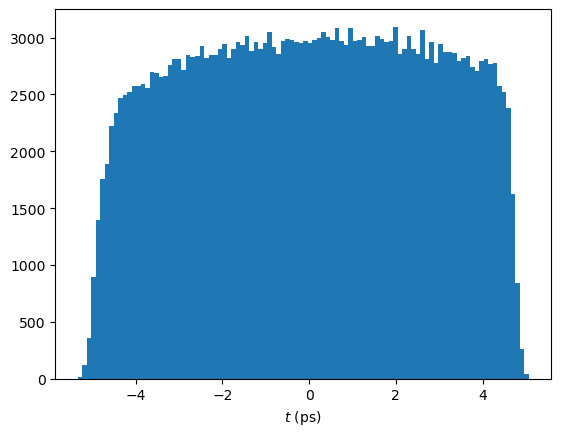

In [52]:
plt.hist(
    (yag4['data']['time']-yag4['data']['time'].mean())*1e12,
    bins=100
)
plt.xlabel('$t$ (ps)')
plt.show()